# Foraging manuscript — Basic Analysis (25 Nov 2026)



In [ ]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import spearmanr, ttest_rel
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D
from IPython.display import display
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ------------------------------------------------------------
# File paths: adjust if automatic discovery does not find data
# ------------------------------------------------------------
PROJECT_ROOT = Path(r"C:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP-main")
SUBJECT_CSV = None
PLANET_CSV = None
REPLICATION_CSV = None     # Set to the FINAL replication subject-level CSV; see below
ALPHA_MAPPING_CSV = None   # Optional: alpha -> modal K lookup CSV, if available
COHORT = "PCL_complete"    # Original exploratory sample (manuscript N=147); "all" for broader checks

# "z_log_second" is the advisor-requested within-subject standardized log second-dig RT.
# Other choices: "log_second", "raw_second", "raw_first".
RT_FIGURE_MODE = "raw_second"
N_BOOT = 1000             # Final mediation analysis; 1000 for quick development
RNG_SEED = 123
EXPORT_DPI = 500
OUTPUT_DIR = Path.cwd() / "manuscript_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {'poor':'#d98186','neutral':'#7699c8','rich':'#69a986',
          'blue':'#316997','red':'#c15c64','orange':'#d58e51','green':'#568b63'}
LABEL_GENERAL = 'General Unpredictability'
LABEL_BASE = 'Baseline discounting'
LABEL_COEF = 'Uncertainty-adaptive discounting'
LABEL_OVERHARVEST = 'Overharvesting (PRT − MVT)'
STATS_ROWS = []

sns.set_theme(style='white')
mpl.rcParams.update({
    'font.family':'DejaVu Sans', 'font.size':14, 'axes.labelsize':16,
    'xtick.labelsize':12, 'ytick.labelsize':12, 'axes.linewidth':1.3,
    'figure.facecolor':'white','savefig.facecolor':'white',
    'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none'
})

def find_csv(explicit, candidates, required=True):
    if explicit is not None:
        p = Path(explicit).expanduser()
        if not p.is_file(): raise FileNotFoundError(f'CSV not found: {p}')
        return p
    roots = [PROJECT_ROOT, Path.cwd(), *list(Path.cwd().parents)[:3]]
    for root in roots:
        for relative in candidates:
            p = root / relative
            if p.is_file(): return p
    if required:
        raise FileNotFoundError(f'Data CSV not located. Set explicit path. Searched: {candidates}')
    return None

SUBJECT_PATH = find_csv(SUBJECT_CSV, [
    'data/result_df/all_foraging_data_07_02_24_with_PCL_factors_LEC.csv',
    'result_df/all_foraging_data_07_02_24_with_PCL_factors_LEC.csv',
    'all_foraging_data_07_02_24_with_PCL_factors_LEC.csv',
])
PLANET_PATH = find_csv(PLANET_CSV, [
    'data/semi_raw_data/all_foraging_data_massive_ae_07_02_24.csv',
    'semi_raw_data/all_foraging_data_massive_ae_07_02_24.csv',
    'all_foraging_data_massive_ae_07_02_24.csv',
])
# Replication dataset is intentionally NOT auto-selected by a broad wildcard.
# Supply the exact subject summary file to avoid fitting to a raw/trial table.
REPLICATION_PATH = find_csv(REPLICATION_CSV, [], required=False)
MAPPING_PATH = find_csv(ALPHA_MAPPING_CSV, [
    'data/modeling_data/alpha_bin_intervals_modeK.csv',
    'alpha_bin_intervals_modeK.csv'
], required=False)
print('Original subject CSV:', SUBJECT_PATH)
print('Original planet CSV:', PLANET_PATH)
print('Replication CSV:', REPLICATION_PATH or 'NOT CONFIGURED — Figure 6/replication alpha will skip')
print('Output:', OUTPUT_DIR)

Original subject CSV: C:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP-main\data\result_df\all_foraging_data_07_02_24_with_PCL_factors_LEC.csv
Original planet CSV: C:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP-main\data\semi_raw_data\all_foraging_data_massive_ae_07_02_24.csv
Replication CSV: NOT CONFIGURED — Figure 6/replication alpha will skip
Output: c:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP_github\foraging_MQLP_2026\data_analysis_new\manuscript_figures


In [18]:
# ------------------------------------------------------------
# Load and validate fileID-level data
# ------------------------------------------------------------
subjects_full = pd.read_csv(SUBJECT_PATH, low_memory=False)
planets_full = pd.read_csv(PLANET_PATH, low_memory=False)

def clean_subject_table(data, name):
    out = data.copy()
    if 'fileID' not in out.columns: raise KeyError(f'{name}: fileID column missing')
    out['fileID'] = out['fileID'].astype('string').str.strip()
    out.loc[out['fileID'].eq('') | out['fileID'].eq('<NA>'), 'fileID'] = pd.NA
    if out['fileID'].isna().any() or out['fileID'].duplicated().any():
        raise ValueError(f'{name}: fileID must be present and unique; do not deduplicate arbitrarily')
    return out

subjects_full = clean_subject_table(subjects_full, 'Original subject file')
if COHORT == 'PCL_complete':
    if 'PCL_Total' not in subjects_full: raise KeyError('PCL_Total required for the exploratory 147 cohort')
    subjects = subjects_full.loc[pd.to_numeric(subjects_full.PCL_Total, errors='coerce').notna()].copy()
elif COHORT == 'all':
    subjects = subjects_full.copy()
else:
    raise ValueError('COHORT must be PCL_complete or all')

planets_full['fileID'] = planets_full['fileID'].astype('string').str.strip()
planets = planets_full.loc[planets_full.fileID.isin(subjects.fileID)].copy()
required_planet = ['block','planet','galaxy','prt','prt_rel_mvt','rt_list']
for col in required_planet:
    if col not in planets: raise KeyError(f'Planet data missing {col}')
for col in ['block','planet','galaxy','prt','prt_rel_mvt']:
    planets[col] = pd.to_numeric(planets[col], errors='coerce')
required_subject = ['FA_factor_1','gamma_base','gamma_coef','prt_avg_rel_mvt',
                    'PCL_Total','Factor_1','Factor_2','Factor_3']
for col in required_subject:
    if col not in subjects: raise KeyError(f'Original subject data missing {col}')
for col in subjects.columns.difference(['fileID']):
    if col in required_subject or col.startswith('FA_factor_') or col.startswith('LEC_') or col.startswith('prt_avg_rel_mvt') or col=='alpha':
        subjects[col] = pd.to_numeric(subjects[col], errors='coerce').replace([np.inf,-np.inf],np.nan)

print(f'Original subject records: {len(subjects_full)} | analysis cohort: {len(subjects)} | planets: {len(planets)}')
print(f'Unique original fileIDs: {subjects.fileID.nunique()} | planet fileIDs: {planets.fileID.nunique()}')
if COHORT == 'PCL_complete' and len(subjects)!=147:
    print('WARNING: exploratory manuscript reports N=147; check exclusion/sample construction.')
missing_ids=set(subjects.fileID)-set(planets.fileID)
if missing_ids: print('WARNING: subject IDs missing planet records:', sorted(missing_ids)[:20])

replication = None
if REPLICATION_PATH is not None:
    replication = clean_subject_table(pd.read_csv(REPLICATION_PATH, low_memory=False), 'Replication summary')
    for col in replication.columns.difference(['fileID']):
        if col.startswith(('FA_factor_', 'Factor_', 'LEC_', 'prt_avg_rel_mvt')) or col in ['gamma_base','gamma_coef','PCL_Total','alpha']:
            replication[col] = pd.to_numeric(replication[col], errors='coerce').replace([np.inf,-np.inf], np.nan)
    print('Replication summary N:', len(replication))
    if len(replication)!=197:
        print('WARNING: manuscript replication N=197; check exclusions and source file.')

Original subject records: 297 | analysis cohort: 147 | planets: 8284
Unique original fileIDs: 147 | planet fileIDs: 147


In [24]:
# ------------------------------------------------------------
# Common statistics, plotting, and data integrity helpers
# ------------------------------------------------------------
def required(data, cols, label):
    missing=[c for c in cols if c not in data.columns]
    if missing: raise KeyError(f'{label}: missing columns {missing}')

def complete_xy(table,x,y):
    required(table,[x,y],'Correlation')
    d=table[[x,y]].copy()
    for c in (x,y): d[c]=pd.to_numeric(d[c], errors='coerce')
    return d.replace([np.inf,-np.inf],np.nan).dropna()

def format_p(p):
    return 'p < .001' if p < .001 else f'p = {p:.3f}'.replace('0.','.')

def star(p):
    return '***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns'

def corr_stats(table,x,y,panel):
    d=complete_xy(table,x,y)
    if len(d)<4 or d[x].nunique()<2 or d[y].nunique()<2:
        raise ValueError(f'{panel}: too few or constant observations for {x}, {y}: N={len(d)}')
    rho,p=spearmanr(d[x],d[y])
    STATS_ROWS.append(dict(panel=panel,statistic='Spearman rho',x=x,y=y,n=len(d),value=rho,p=p))
    return d,float(rho),float(p)

def paired_test(wide,x,y,panel):
    d=wide[[x,y]].replace([np.inf,-np.inf],np.nan).dropna()
    if len(d)<3: raise ValueError(f'{panel}: need >=3 paired participants')
    t,p=ttest_rel(d[x],d[y])
    STATS_ROWS.append(dict(panel=panel,statistic='paired t',x=x,y=y,n=len(d),value=t,p=p))
    return float(t),float(p),int(len(d))

def panel_letter(ax,letter):
    ax.text(-.10,1.04,letter,transform=ax.transAxes,fontsize=24,fontweight='normal',
            ha='left',va='bottom',clip_on=False)

def base_axes(ax):
    ax.grid(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.tick_params(length=4,width=1.1)

def save_figure(fig,stem):
    for ext in ('png','pdf','svg'):
        kwargs={'dpi':EXPORT_DPI} if ext=='png' else {}
        fig.savefig(OUTPUT_DIR/f'{stem}.{ext}',bbox_inches='tight',facecolor='white',**kwargs)
    print('Saved:',OUTPUT_DIR/f'{stem}.png')

def scatter_panel(ax,table,x,y,xlabel,ylabel,color,letter,panel,size=32,annot=True):
    d,rho,p=corr_stats(table,x,y,panel)
    ax.scatter(d[x],d[y],s=size,alpha=.62,facecolor=color,
               edgecolors='white',linewidths=.3,rasterized=True)
    slope,intercept=np.polyfit(d[x].to_numpy(),d[y].to_numpy(),1)
    xs=np.linspace(d[x].min(),d[x].max(),120)
    ax.plot(xs,slope*xs+intercept,lw=2.2,color=color)
    ax.set_xlabel(xlabel);ax.set_ylabel(ylabel)
    if annot:
        ax.text(.02,1.015,f'ρ = {rho:.2f}, {format_p(p)}' + (star(p) if p<.05 else ''),
                transform=ax.transAxes,ha='left',va='bottom',fontsize=11.3)
    base_axes(ax);panel_letter(ax,letter)
    return d,rho,p

def bracket(ax,x1,x2,p,level=0):
    lo,hi=ax.get_ylim();span=hi-lo
    y=hi+(0.045+.16*level)*span; h=.028*span
    ax.plot([x1,x1,x2,x2],[y,y+h,y+h,y],color='black',lw=1.2,clip_on=False)
    ax.text((x1+x2)/2,y+h+.02*span,star(p),ha='center',va='bottom',fontsize=15,clip_on=False)
    ax.set_ylim(lo,hi+(.23+.16*level)*span)

def participant_boxes(ax,wide,cols,ticks,colors,ylabel,letter):
    vals=[wide[c].dropna().to_numpy(dtype=float) for c in cols]
    parts=ax.boxplot(vals,positions=np.arange(len(cols)),widths=.60,showfliers=False,
                     patch_artist=True,medianprops={'color':'#222','linewidth':1.5})
    for patch,color in zip(parts['boxes'],colors):
        patch.set_facecolor(color);patch.set_alpha(.22);patch.set_edgecolor(color)
    jitter=np.random.default_rng(RNG_SEED)
    for j,(a,color) in enumerate(zip(vals,colors)):
        ax.scatter(j+jitter.uniform(-.20,.20,len(a)),a,s=19,alpha=.33,
                   color=color,linewidths=0,rasterized=True)
        if len(a):
            ax.scatter(j,np.mean(a),marker='X',c='white',edgecolors='#333',s=145,lw=1.2,zorder=5)
    ax.set_xticks(np.arange(len(cols)),ticks);ax.set_ylabel(ylabel)
    base_axes(ax);panel_letter(ax,letter)

def parse_rt_list(value):
    if isinstance(value,(list,tuple,np.ndarray)): return list(value)
    if isinstance(value,str):
        try:
            v=ast.literal_eval(value)
            if isinstance(v,(list,tuple,np.ndarray)): return list(v)
        except (ValueError,SyntaxError): pass
    return []

def rt_at(v,index):
    values=parse_rt_list(v)
    return pd.to_numeric(values[index],errors='coerce') if len(values)>index else np.nan

def complete_case(data, cols):
    required(data,cols,'Model')
    d=data[cols].copy()
    for col in cols: d[col]=pd.to_numeric(d[col],errors='coerce')
    return d.replace([np.inf,-np.inf],np.nan).dropna().reset_index(drop=True)

def mean_ci(samples):
    vals=np.asarray(samples,float)
    vals=vals[np.isfinite(vals)]
    if len(vals)==0: raise ValueError('No valid bootstrap samples')
    return np.quantile(vals,[.025,.975])

def fdr_valid(p):
    a=np.asarray(p,float)
    q=np.full(len(a),np.nan)
    good=np.isfinite(a)
    if good.any():q[good]=multipletests(a[good],method='fdr_bh')[1]
    return q

## Figure 3 — task structure, RT sensitivity analysis, and early/late learning

**Advisor comment:** compare *second-dig* RTs on the log scale, optionally standardized within participant before aggregating switch/no-switch conditions. The notebook reports four candidate RT definitions and draws panel B using `RT_FIGURE_MODE` from configuration. The y-axis is always labeled with the actual statistic used; update the Results to match the printed Figure 3B result after running. Block-starting planets are not labeled as transitions.

Observed switch labels: 0 mismatches / 7549 comparisons
Converted rt_first from milliseconds to seconds
Converted rt_second from milliseconds to seconds

RT alternatives, not interchangeable:
        mode   n      t        p  mean_switch  mean_no_switch
  raw_second 147 2.3048 0.022587      0.49108         0.46911
  log_second 147 1.2239  0.22298      -1.1267         -1.1664
z_log_second 147 2.0157 0.045669     0.032782        -0.02999
Learning blocks 1 -> 5: N=147, t(146)=-7.8995, p=6.19498e-13
Mean |PRT-MVT| early=2.512, late=1.454
Figure 3B (selected RT mode): N=147, t(146)=2.3048, p=0.0225869
Figure 3C: N=147, t(146)=6.6235, p=6.28243e-10
Saved: c:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP_github\foraging_MQLP_2026\data_analysis_new\manuscript_figures\Figure3.png


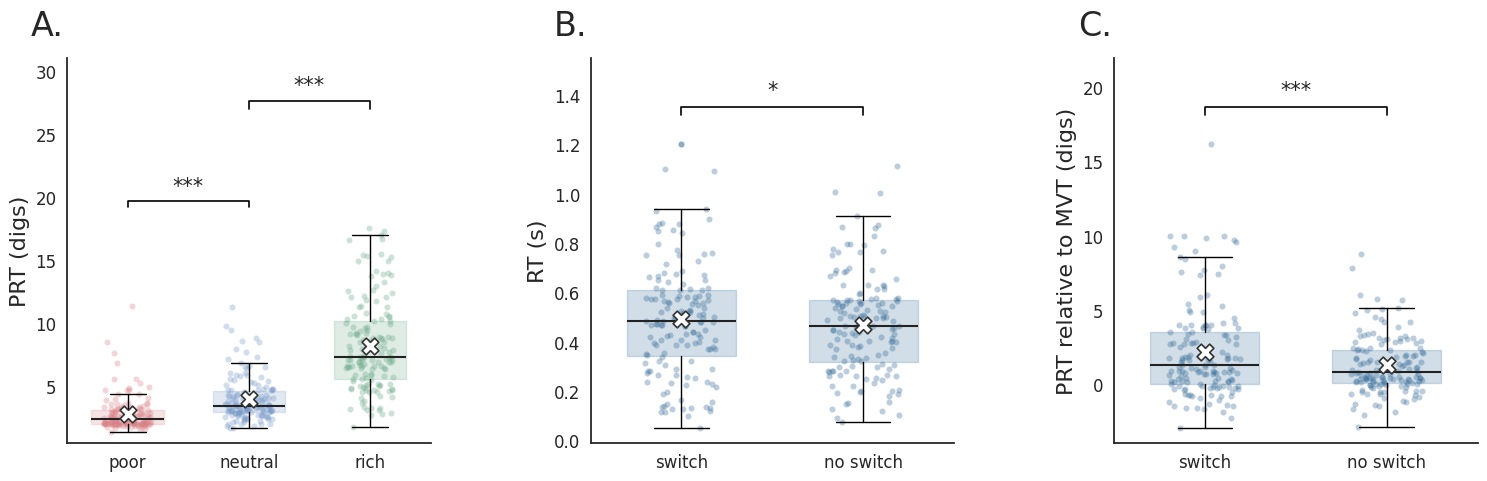

In [32]:
# Define transitions from original chronological records before excluding missing outcomes.
p3=planets.dropna(subset=['fileID','block','planet']).copy()
p3=p3.sort_values(['fileID','block','planet'],kind='stable')
if p3.duplicated(['fileID','block','planet']).any():
    raise ValueError('Duplicate fileID/block/planet order; inspect before analyzing transitions')
p3['prev_galaxy']=p3.groupby(['fileID','block'])['galaxy'].shift(1)
p3['transition']=pd.NA
valid=p3['galaxy'].notna() & p3['prev_galaxy'].notna()
p3.loc[valid,'transition']=np.where(
    p3.loc[valid,'galaxy']!=p3.loc[valid,'prev_galaxy'],'switch','no switch')

# Verify independently recorded transition status if present.
if 'switch_point' in p3.columns:
    recorded=(p3.loc[valid,'switch_point'].astype('string').str.strip().str.lower()
              .map({'true':'switch','false':'no switch','1':'switch','0':'no switch'}))
    comparable=recorded.notna()
    mismatches=(recorded[comparable]!=p3.loc[valid].loc[comparable,'transition']).sum()
    print(f'Observed switch labels: {mismatches} mismatches / {int(comparable.sum())} comparisons')
    if mismatches: raise ValueError('Derived transitions do not match switch_point labels')

p3['rt_first']=p3['rt_list'].map(lambda v: rt_at(v,0))
p3['rt_second']=p3['rt_list'].map(lambda v: rt_at(v,1))
for col in ['rt_first','rt_second']:
    med=p3[col].median()
    if np.isfinite(med) and med>20:  # same uniform-unit check as prior notebook
        p3[col]=p3[col]/1000
        print(f'Converted {col} from milliseconds to seconds')

# Nonpositive RTs cannot be logged; excluded only from log-based analyses.
p3['log_rt_second']=np.log(p3['rt_second'].where(p3['rt_second']>0))
# Within-person standardized across *all second-dig observations* (not per condition).
mean_by_id=p3.groupby('fileID')['log_rt_second'].transform('mean')
sd_by_id=p3.groupby('fileID')['log_rt_second'].transform('std')
p3['z_log_rt_second']=(p3['log_rt_second']-mean_by_id)/sd_by_id.where(sd_by_id>0)
rt_modes={
    'raw_second':('rt_second','RT (s)'),
    'log_second':('log_rt_second','log RT (s)'),
    'z_log_second':('z_log_rt_second','z(log RT)')
}
if RT_FIGURE_MODE not in rt_modes:raise ValueError('Unknown RT_FIGURE_MODE')
tr=p3.loc[p3['transition'].notna()].copy()

def transition_means(col):
    return tr.groupby(['fileID','transition'],observed=True)[col].mean().unstack('transition')

rt_comparisons=[]
for mode,(col,ylab) in rt_modes.items():
    w=transition_means(col)
    if not {'switch','no switch'}.issubset(w.columns):raise ValueError('Missing RT transition category')
    t,p,n=paired_test(w,'switch','no switch',f'Figure 3B RT sensitivity: {mode}')
    rt_comparisons.append(dict(mode=mode,n=n,t=t,p=p,mean_switch=w['switch'].mean(),
                               mean_no_switch=w['no switch'].mean()))
rt_stats=pd.DataFrame(rt_comparisons)
print('\nRT alternatives, not interchangeable:')
print(rt_stats.to_string(index=False,float_format=lambda x:f'{x:.5g}'))
rt_wide=transition_means(rt_modes[RT_FIGURE_MODE][0])
prt_wide=transition_means('prt_rel_mvt')
richness=(p3.dropna(subset=['galaxy','prt'])
          .groupby(['fileID','galaxy'],observed=True)['prt'].mean()
          .unstack('galaxy').rename(columns={0:'poor',1:'neutral',2:'rich'}))
if not {'poor','neutral','rich'}.issubset(richness.columns):
    raise ValueError('Missing poor/neutral/rich categories')

# First vs last block: per-person mean of absolute planet-level PRT - MVT deviations.
p3['abs_dev_mvt']=p3['prt_rel_mvt'].abs()
block_dev=p3.groupby(['fileID','block'])['abs_dev_mvt'].mean().unstack('block')
blocks=sorted(block_dev.columns.dropna())
if len(blocks)<2:raise ValueError('At least two blocks needed for early-vs-late learning')
early,late=blocks[0],blocks[-1]
learning=block_dev[[early,late]].dropna()
t_learn,p_learn,n_learn=paired_test(learning,late,early,'Figure 3 early vs late abs deviation')
print(f'Learning blocks {early} -> {late}: N={n_learn}, t({n_learn-1})={t_learn:.4f}, p={p_learn:.6g}')
print(f'Mean |PRT-MVT| early={learning[early].mean():.3f}, late={learning[late].mean():.3f}')

fig,axs=plt.subplots(1,3,figsize=(18.2,5))
participant_boxes(axs[0],richness,['poor','neutral','rich'],['poor','neutral','rich'],
                  [COLORS['poor'],COLORS['neutral'],COLORS['rich']],'PRT (digs)','A.')
_,p01,_=paired_test(richness,'neutral','poor','Figure 3A neutral vs poor')
_,p12,_=paired_test(richness,'rich','neutral','Figure 3A rich vs neutral')
bracket(axs[0],0,1,p01,level=0)
bracket(axs[0],1,2,p12,level=1)
for ax,w,ylab,letter,panel in [
    (axs[1],rt_wide,rt_modes[RT_FIGURE_MODE][1],'B.','Figure 3B (selected RT mode)'),
    (axs[2],prt_wide,'PRT relative to MVT (digs)','C.','Figure 3C')]:
    participant_boxes(ax,w,['switch','no switch'],['switch','no switch'],
                      [COLORS['blue'],COLORS['blue']],ylab,letter)
    t,p,n=paired_test(w,'switch','no switch',panel)
    bracket(ax,0,1,p)
    print(f'{panel}: N={n}, t({n-1})={t:.4f}, p={p:.6g}')
fig.subplots_adjust(wspace=.44)
save_figure(fig,'Figure3')
plt.show()
rt_stats.to_csv(OUTPUT_DIR/'Figure3_RT_sensitivity.csv',index=False)

## Figure 4 — core parameter–behavior correlations


Saved: c:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP_github\foraging_MQLP_2026\data_analysis_new\manuscript_figures\Figure4.png


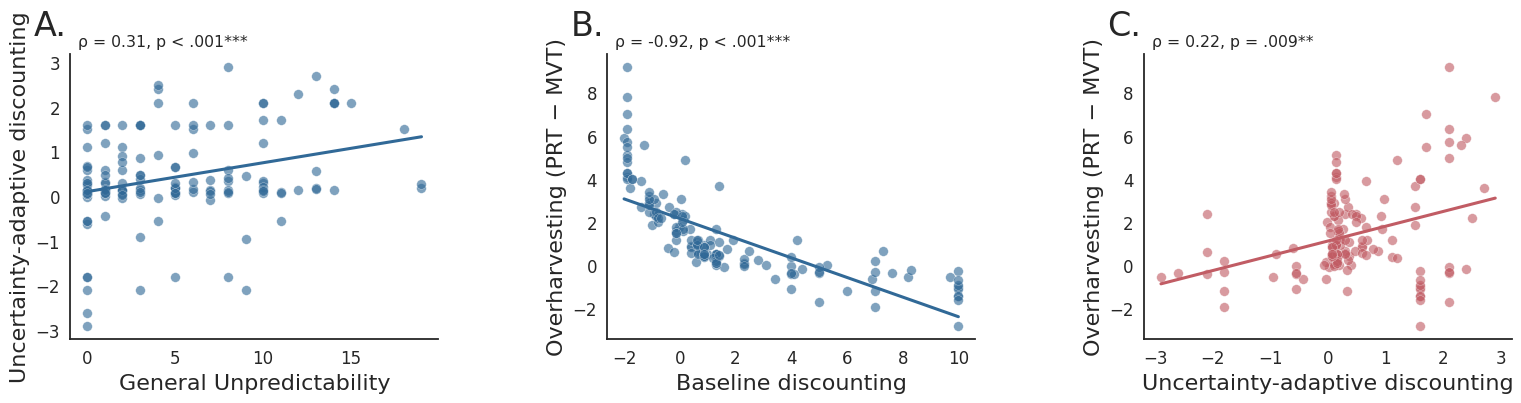

In [26]:
fig,axs=plt.subplots(1,3,figsize=(18.6,4.6))
specs=[
    ('FA_factor_1','gamma_coef',LABEL_GENERAL,LABEL_COEF,COLORS['blue'],'A.','Figure 4A'),
    ('gamma_base','prt_avg_rel_mvt',LABEL_BASE,LABEL_OVERHARVEST,COLORS['blue'],'B.','Figure 4B'),
    ('gamma_coef','prt_avg_rel_mvt',LABEL_COEF,LABEL_OVERHARVEST,COLORS['red'],'C.','Figure 4C'),
]
for ax,(x,y,xlab,ylab,color,letter,panel) in zip(axs,specs):
    scatter_panel(ax,subjects,x,y,xlab,ylab,color,letter,panel,size=48)
fig.subplots_adjust(wspace=.46,bottom=.21,top=.83)
save_figure(fig,'Figure4')
plt.show()

## Figure 5A–D — PTSD symptom correlations

All parameter axes now display **Uncertainty-adaptive discounting** and all ELU axes **General Unpredictability**. In panels C and D, the scatter cloud is shown separately for each PCL factor with a separate Spearman statistic in the legend.

Saved: c:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP_github\foraging_MQLP_2026\data_analysis_new\manuscript_figures\Figure5.png


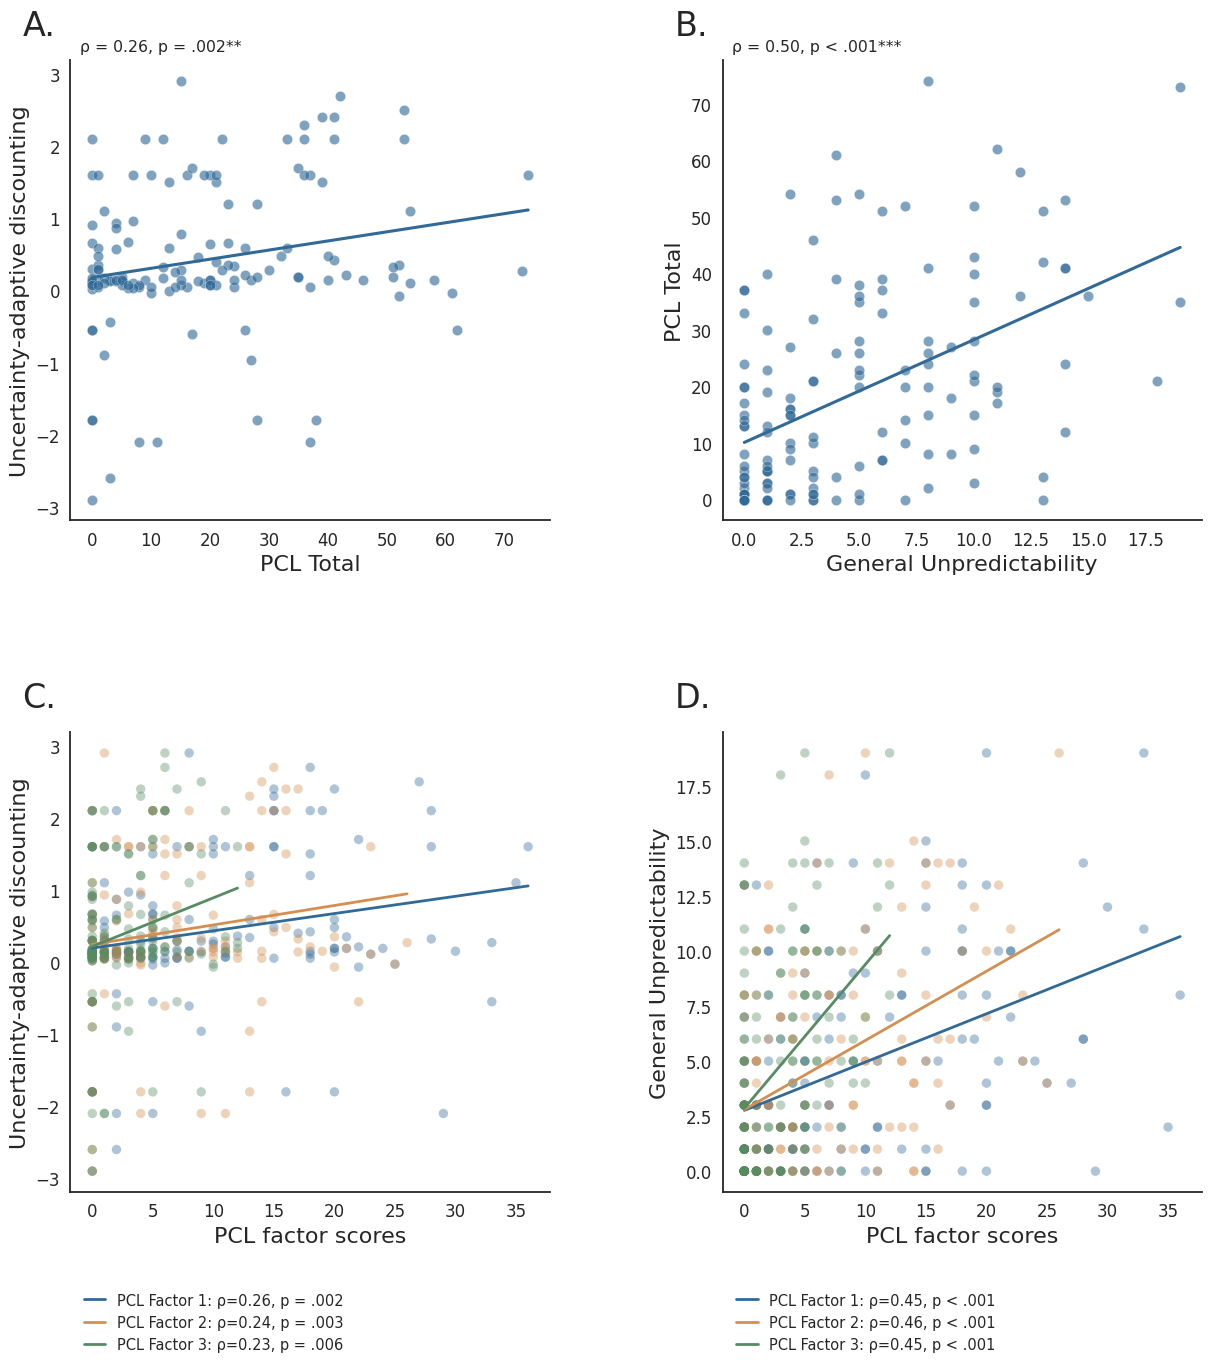

In [27]:
PCL_FACTORS=['Factor_1','Factor_2','Factor_3']
PCL_COLORS=[COLORS['blue'],COLORS['orange'],COLORS['green']]

def multi_factor_panel(ax,data,y,ylabel,letter,panel):
    handles=[]
    for idx,(x,color) in enumerate(zip(PCL_FACTORS,PCL_COLORS),start=1):
        d,r,p=corr_stats(data,x,y,f'{panel}: PCL Factor {idx}')
        ax.scatter(d[x],d[y],s=46,alpha=.39,color=color,edgecolors='none',rasterized=True)
        slope,intercept=np.polyfit(d[x].to_numpy(),d[y].to_numpy(),1)
        xs=np.linspace(d[x].min(),d[x].max(),120)
        ax.plot(xs,slope*xs+intercept,lw=2,color=color)
        handles.append(Line2D([0],[0],color=color,lw=2,
            label=f'PCL Factor {idx}: ρ={r:.2f}, {format_p(p)}'))
    ax.set_xlabel('PCL factor scores');ax.set_ylabel(ylabel)
    base_axes(ax);panel_letter(ax,letter)
    ax.legend(handles=handles,loc='upper left',bbox_to_anchor=(0,-.19),
              frameon=False,fontsize=10.5,handlelength=1.5)

fig,axs=plt.subplots(2,2,figsize=(14.6,13.8))
scatter_panel(axs[0,0],subjects,'PCL_Total','gamma_coef','PCL Total',LABEL_COEF,
              COLORS['blue'],'A.','Figure 5A',size=55)
scatter_panel(axs[0,1],subjects,'FA_factor_1','PCL_Total',LABEL_GENERAL,'PCL Total',
              COLORS['blue'],'B.','Figure 5B',size=55)
multi_factor_panel(axs[1,0],subjects,'gamma_coef',LABEL_COEF,'C.','Figure 5C')
multi_factor_panel(axs[1,1],subjects,'FA_factor_1',LABEL_GENERAL,'D.','Figure 5D')
fig.subplots_adjust(wspace=.36,hspace=.46,bottom=.11,top=.93)
save_figure(fig,'Figure5')
plt.show()

## Mediation models (original exploratory sample)

Each participant enters once (`fileID` unique). The original-study models use **unstandardized** linear mediation for the ELU → `gamma_coef` → PRT−MVT pathway, and **standardized** coefficients for ELU → PCL → `gamma_coef` controlling for each LEC index. The same bootstrap resamples the complete subject rows for every path. Bootstrap intervals are percentile CIs and are exported verbatim (no approximate or handwritten endpoints).

In [28]:
X='FA_factor_1'; COEF='gamma_coef'; BASE='gamma_base'; PCL='PCL_Total'
LEC=['LEC_Conservative','LEC_Stringent','LEC_Liberal']
OUTCOMES={'Poor':'prt_avg_rel_mvt_poor','Neutral':'prt_avg_rel_mvt_mid',
          'Rich':'prt_avg_rel_mvt_rich','Overall':'prt_avg_rel_mvt'}

def prepared_mediation(data,variables,standardize=False,rank_based=False):
    d=complete_case(data,variables)
    if len(d)<10:raise ValueError(f'Too few complete cases for mediation: N={len(d)}')
    if rank_based:
        d=d.rank(axis=0,method='average')
        standardize=True
    if standardize:
        sd=d.std(ddof=0)
        if (sd<=0).any():raise ValueError('Constant mediation variable')
        d=(d-d.mean())/sd
    return d

def ols_mediation(data,x,m,y,covars=(),standardize=False,rank_based=False,
                  n_boot=1000,seed=123):
    cols=list(dict.fromkeys([x,m,y]+list(covars)))
    d=prepared_mediation(data,cols,standardize,rank_based)
    xarr=d[x].to_numpy(float); marr=d[m].to_numpy(float); yarr=d[y].to_numpy(float)
    cv=d[list(covars)].to_numpy(float) if covars else np.empty((len(d),0))
    A=np.column_stack([np.ones(len(d)),xarr,cv])
    B=np.column_stack([np.ones(len(d)),xarr,marr,cv])
    ma=sm.OLS(marr,A).fit(); mb=sm.OLS(yarr,B).fit(); mc=sm.OLS(yarr,A).fit()
    rng=np.random.default_rng(seed)
    ab=np.empty(n_boot,float)
    for i in range(n_boot):
        ii=rng.integers(0,len(d),len(d))
        ai=np.linalg.lstsq(A[ii],marr[ii],rcond=None)[0][1]
        bi=np.linalg.lstsq(B[ii],yarr[ii],rcond=None)[0][2]
        ab[i]=ai*bi
    lo,hi=mean_ci(ab)
    # Finite two-sided bootstrap sign test (exploratory summary, not a mediation test p-value).
    p_boot=2*min((np.count_nonzero(ab<=0)+1)/(n_boot+1),
                 (np.count_nonzero(ab>=0)+1)/(n_boot+1))
    return dict(N=len(d),a=float(ma.params[1]),a_p=float(ma.pvalues[1]),
                b=float(mb.params[2]),b_p=float(mb.pvalues[2]),
                c_total=float(mc.params[1]),c_total_p=float(mc.pvalues[1]),
                c_prime=float(mb.params[1]),c_prime_p=float(mb.pvalues[1]),
                indirect_ab=float(ma.params[1]*mb.params[2]),
                CI_low=float(lo),CI_high=float(hi),
                bootstrap_sign_p=float(min(1,p_boot)),n_boot=n_boot)

required(subjects,[X,COEF,BASE,PCL]+LEC+list(OUTCOMES.values()),'Original mediation')
med_main=pd.DataFrame([
    dict(environment=env,**ols_mediation(subjects,X,COEF,y,n_boot=N_BOOT,seed=RNG_SEED+i))
    for i,(env,y) in enumerate(OUTCOMES.items())
])
med_main['q_env_indirect']=np.nan
subset=med_main.environment.isin(['Poor','Neutral','Rich'])
med_main.loc[subset,'q_env_indirect']=fdr_valid(med_main.loc[subset,'bootstrap_sign_p'])
print('\nOriginal single mediation:');display(med_main.round(4))
med_main.to_csv(OUTPUT_DIR/'Original_ELU_gamma_overharvesting_mediation.csv',index=False)

# Parallel mediation, with a single paired bootstrap for all pathways.
def parallel_mediation(data,x,m1,m2,y,n_boot=N_BOOT,seed=123):
    d=prepared_mediation(data,[x,m1,m2,y])
    v=d[[x,m1,m2,y]].to_numpy(float)
    n=len(v);xx=v[:,0];mm1=v[:,1];mm2=v[:,2];yy=v[:,3]
    A=np.column_stack([np.ones(n),xx])
    B=np.column_stack([np.ones(n),xx,mm1,mm2])
    a1=sm.OLS(mm1,A).fit();a2=sm.OLS(mm2,A).fit()
    b=sm.OLS(yy,B).fit();c=sm.OLS(yy,A).fit()
    rng=np.random.default_rng(seed);boots=np.empty((n_boot,3))
    for i in range(n_boot):
        ii=rng.integers(0,n,n)
        aa1=np.linalg.lstsq(A[ii],mm1[ii],rcond=None)[0][1]
        aa2=np.linalg.lstsq(A[ii],mm2[ii],rcond=None)[0][1]
        bb=np.linalg.lstsq(B[ii],yy[ii],rcond=None)[0]
        boots[i,:]=[aa1*bb[2],aa2*bb[3],aa1*bb[2]+aa2*bb[3]]
    ci=np.percentile(boots,[2.5,97.5],axis=0)
    result=dict(N=n,c_total=c.params[1],c_total_p=c.pvalues[1],
                c_prime=b.params[1],c_prime_p=b.pvalues[1],
                a_gamma_coef=a1.params[1],a_gamma_coef_p=a1.pvalues[1],
                a_gamma_base=a2.params[1],a_gamma_base_p=a2.pvalues[1],
                b_gamma_coef=b.params[2],b_gamma_coef_p=b.pvalues[2],
                b_gamma_base=b.params[3],b_gamma_base_p=b.pvalues[3],
                indirect_gamma_coef=a1.params[1]*b.params[2],
                coef_CI_low=ci[0,0],coef_CI_high=ci[1,0],
                indirect_gamma_base=a2.params[1]*b.params[3],
                base_CI_low=ci[0,1],base_CI_high=ci[1,1],
                indirect_total=a1.params[1]*b.params[2]+a2.params[1]*b.params[3],
                total_CI_low=ci[0,2],total_CI_high=ci[1,2],n_boot=n_boot)
    return result

med_parallel=pd.DataFrame([parallel_mediation(subjects,X,COEF,BASE,OUTCOMES['Overall'],seed=RNG_SEED+60)])
print('\nOriginal parallel mediation:');display(med_parallel.round(4))
med_parallel.to_csv(OUTPUT_DIR/'Original_parallel_gamma_mediation.csv',index=False)

med_lec=pd.DataFrame([
    dict(covariate=lec,**ols_mediation(subjects,X,PCL,COEF,covars=[lec],
                                     standardize=True,n_boot=N_BOOT,seed=RNG_SEED+i+100))
    for i,lec in enumerate(LEC)
])
print('\nOriginal ELU -> PCL -> gamma_coef adjusted for LEC:');display(med_lec.round(4))
med_lec.to_csv(OUTPUT_DIR/'Original_LEC_adjusted_PCL_mediation.csv',index=False)


Original single mediation:


,environment,N,a,a_p,b,b_p,c_total,c_total_p,c_prime,c_prime_p,indirect_ab,CI_low,CI_high,bootstrap_sign_p,n_boot,q_env_indirect
0,Poor,147,0.0646,0.0002,0.4454,0.0000,0.1103,0.0000,0.0816,0.0001,0.0288,0.0102,0.0524,0.0004,5000,0.0012
1,Neutral,147,0.0646,0.0002,0.5157,0.0002,0.1188,0.0001,0.0855,0.0036,0.0333,0.0090,0.0678,0.0020,5000,0.0030
2,Rich,147,0.0646,0.0002,0.7455,0.0055,0.1585,0.0052,0.1104,0.0555,0.0482,0.0075,0.1013,0.0152,5000,0.0152
3,Overall,147,0.0646,0.0002,0.5594,0.0006,0.1261,0.0003,0.0900,0.0095,0.0361,0.0092,0.0725,0.0048,5000,NaN



Original parallel mediation:


,N,c_total,c_total_p,c_prime,c_prime_p,a_gamma_coef,a_gamma_coef_p,a_gamma_base,a_gamma_base_p,b_gamma_coef,...,indirect_gamma_coef,coef_CI_low,coef_CI_high,indirect_gamma_base,base_CI_low,base_CI_high,indirect_total,total_CI_low,total_CI_high,n_boot
0,147,0.1261,0.0003,0.0592,0.0093,0.0646,0.0002,-0.0864,0.136,0.4611,...,0.0298,0.0103,0.0553,0.0371,-0.0057,0.0749,0.0669,0.0137,0.1181,5000



Original ELU -> PCL -> gamma_coef adjusted for LEC:


,covariate,N,a,a_p,b,b_p,c_total,c_total_p,c_prime,c_prime_p,indirect_ab,CI_low,CI_high,bootstrap_sign_p,n_boot
0,LEC_Conservative,147,0.3117,0.0001,0.1407,0.1447,0.3308,0.0004,0.2869,0.0031,0.0439,-0.0161,0.1175,0.1636,5000
1,LEC_Stringent,147,0.3747,0.0000,0.1016,0.2805,0.2885,0.0012,0.2504,0.0087,0.0381,-0.0342,0.1135,0.2927,5000
2,LEC_Liberal,147,0.3576,0.0000,0.0953,0.3152,0.2781,0.0020,0.2441,0.0108,0.0341,-0.0330,0.1055,0.3139,5000


## Figure 5E — corrected arrow attachment


Saved: c:\Users\zyfxl\OneDrive - UC Irvine\UCI\CCNL Lab\Foraging Task Overview\foraging_MQLP-main\foraging_MQLP_github\foraging_MQLP_2026\data_analysis_new\manuscript_figures\Figure5E.png


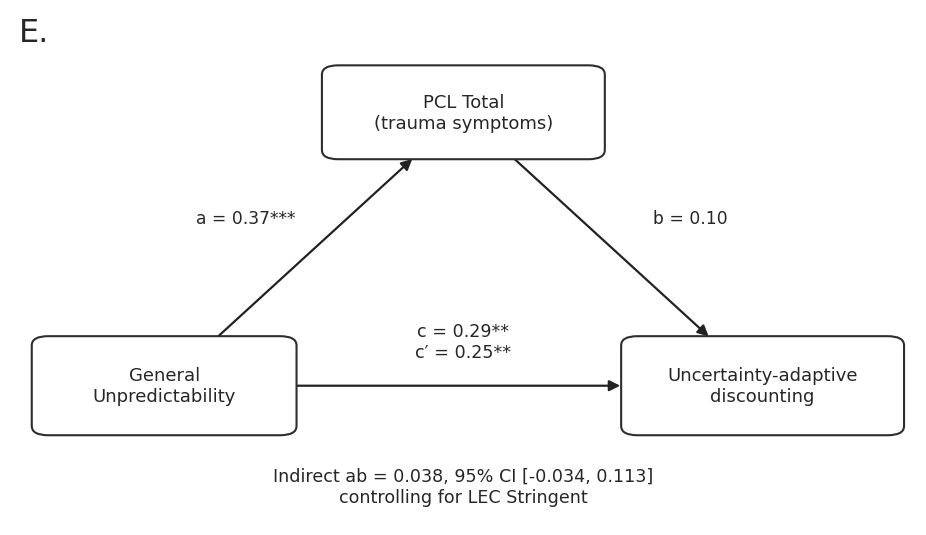

In [29]:
# Use actual results from the above model, not manually copied values.
row=med_lec.loc[med_lec['covariate'].eq('LEC_Stringent')].iloc[0]
fig,ax=plt.subplots(figsize=(11.7,6.7))
ax.set(xlim=(0,1),ylim=(0,1));ax.set_axis_off()

# Nodes in axes-fraction coordinates: center (x,y), width, height.
nodes={
    'X':((.17,.27),.26,.16,'General\nUnpredictability'),
    'M':((.50,.80),.28,.15,'PCL Total\n(trauma symptoms)'),
    'Y':((.83,.27),.28,.16,'Uncertainty-adaptive\ndiscounting'),
}
patches={}
for name,(center,w,h,label) in nodes.items():
    cx,cy=center
    patch=FancyBboxPatch((cx-w/2,cy-h/2),w,h,
                         boxstyle='round,pad=0.016,rounding_size=0.018',
                         linewidth=1.5,edgecolor='#2d2d2d',facecolor='white',
                         transform=ax.transAxes,zorder=3)
    ax.add_patch(patch);patches[name]=patch
    ax.text(cx,cy,label,ha='center',va='center',fontsize=13.0,fontweight='medium',
            transform=ax.transAxes,zorder=4)

def box_endpoint(c1,c2,w,h,gap=.014):
    """Ray from c1 to c2 intersects the first rectangle boundary plus a short gap."""
    v=np.asarray(c2,dtype=float)-np.asarray(c1,dtype=float)
    scales=[]
    if abs(v[0])>1e-10:scales.append((w/2)/abs(v[0]))
    if abs(v[1])>1e-10:scales.append((h/2)/abs(v[1]))
    t=min(scales)
    return np.asarray(c1,dtype=float)+v*t+gap*v/np.linalg.norm(v)

def diagram_arrow(start,end):
    ca,wa,ha,_=nodes[start];cb,wb,hb,_=nodes[end]
    xyA=box_endpoint(ca,cb,wa,ha)
    xyB=box_endpoint(cb,ca,wb,hb)
    arr=FancyArrowPatch(xyA,xyB,arrowstyle='-|>',mutation_scale=16,
                        linewidth=1.6,color='#222222',
                        connectionstyle='arc3,rad=0',
                        transform=ax.transAxes,zorder=2)
    ax.add_patch(arr)
    return xyA,xyB

path_a=diagram_arrow('X','M')
path_b=diagram_arrow('M','Y')
path_direct=diagram_arrow('X','Y')

def path_stars(p):
    return '***' if p<.001 else '**' if p<.01 else '*' if p<.05 else ''

ax.text(.26,.595,f'a = {row.a:.2f}{path_stars(row.a_p)}',fontsize=12.3,
        ha='center',va='center',transform=ax.transAxes)
ax.text(.75,.595,f'b = {row.b:.2f}{path_stars(row.b_p)}',fontsize=12.3,
        ha='center',va='center',transform=ax.transAxes)
ax.text(.50,.355,f'c = {row.c_total:.2f}{path_stars(row.c_total_p)}\n'
                    f"c′ = {row.c_prime:.2f}{path_stars(row.c_prime_p)}",
        fontsize=12.6,ha='center',va='center',transform=ax.transAxes)
ax.text(.50,.075,f'Indirect ab = {row.indirect_ab:.3f}, '
                    f'95% CI [{row.CI_low:.3f}, {row.CI_high:.3f}]\n'
                    'controlling for LEC Stringent',
        fontsize=12.6,ha='center',va='center',transform=ax.transAxes)
ax.text(.01,.985,'E.',fontsize=23,ha='left',va='top',transform=ax.transAxes)

# Assert arrow endpoints are outside geometric rectangles (with at least 0.005 gap).
for (a,b),pair in [(('X','M'),path_a),(('M','Y'),path_b),(('X','Y'),path_direct)]:
    for node,pt in ((a,pair[0]),(b,pair[1])):
        (cx,cy),w,h,_=nodes[node]
        inside=abs(pt[0]-cx)<w/2-1e-6 and abs(pt[1]-cy)<h/2-1e-6
        assert not inside,(a,b,node,pt)

save_figure(fig,'Figure5E')
plt.show()

## Figure 6 — preregistered replication


In [30]:
# Replication results + Figure 6. Deliberately skip if REPLICATION_CSV is not set.
if replication is None:
    print('Figure 6 skipped: set REPLICATION_CSV to your final replication subject summary.')
else:
    rep_needed=[X,COEF,BASE,PCL]+LEC+list(OUTCOMES.values())
    required(replication,rep_needed,'Replication Figure 6')

    # Rank-standardized regression for mediation, as described in the manuscript.
    rep_main=pd.DataFrame([
        dict(environment=env,**ols_mediation(replication,X,COEF,y,
                    rank_based=True,n_boot=N_BOOT,seed=RNG_SEED+1000+i))
        for i,(env,y) in enumerate(OUTCOMES.items())
    ])
    is_env=rep_main.environment.isin(['Poor','Neutral','Rich'])
    rep_main['q_env_indirect']=np.nan
    rep_main.loc[is_env,'q_env_indirect']=fdr_valid(rep_main.loc[is_env,'bootstrap_sign_p'])
    rep_lec=pd.DataFrame([
        dict(covariate=lec,**ols_mediation(replication,X,PCL,COEF,
                       covars=[lec],rank_based=True,n_boot=N_BOOT,
                       seed=RNG_SEED+1100+i))
        for i,lec in enumerate(LEC)
    ])
    rep_lec['q_indirect']=fdr_valid(rep_lec['bootstrap_sign_p'])
    rep_main.to_csv(OUTPUT_DIR/'Replication_gamma_mediation.csv',index=False)
    rep_lec.to_csv(OUTPUT_DIR/'Replication_LEC_PCL_mediation.csv',index=False)
    print('Figure 6C mediation:');display(rep_main.round(4))
    print('Figure 6F mediation:');display(rep_lec.round(4))

    def ci_forest(ax,table,labels,color_lookup,stem):
        positions=np.arange(len(table))[::-1]
        lower=table['CI_low'].to_numpy(float)
        upper=table['CI_high'].to_numpy(float)
        means=table['indirect_ab'].to_numpy(float)
        if np.any(upper<lower) or np.any(means<lower) or np.any(means>upper):
            raise ValueError(f'{stem}: inconsistent bootstrap CI and point estimates')
        for i,(p,estimate,lo,hi) in enumerate(zip(positions,means,lower,upper)):
            color=color_lookup[i]
            ax.errorbar(estimate,p,xerr=[[estimate-lo],[hi-estimate]],fmt='o',
                        capsize=2.5,lw=1.6,markersize=5,color=color,
                        markerfacecolor=color,ecolor=color)
        ax.axvline(0,color='#777',lw=1.1,ls='--',zorder=0)
        all_x=np.r_[lower,upper,means,0.]
        span=float(all_x.max()-all_x.min())
        margin=max(.012,.11*span)
        ax.set_xlim(all_x.min()-margin,all_x.max()+margin)
        ax.set_ylim(-.6,len(table)-.4)
        ax.set_yticks(positions,labels)
        ax.set_xlabel('Indirect effect (ab)')
        base_axes(ax)

    fig,axs=plt.subplots(2,3,figsize=(18.5,11.0))
    scatter_panel(axs[0,0],replication,X,COEF,LABEL_GENERAL,LABEL_COEF,
                  COLORS['blue'],'A.','Figure 6A',size=35)
    scatter_panel(axs[0,1],replication,COEF,'prt_avg_rel_mvt',LABEL_COEF,
                  LABEL_OVERHARVEST,COLORS['red'],'B.','Figure 6B',size=35)
    ci_forest(axs[0,2],rep_main,['Overall','Poor','Neutral','Rich'],
              ['#393939',COLORS['red'],COLORS['blue'],COLORS['green']],'Figure 6C')
    panel_letter(axs[0,2],'C.')
    scatter_panel(axs[1,0],replication,PCL,COEF,'PCL Total',LABEL_COEF,
                  COLORS['green'],'D.','Figure 6D',size=35)
    scatter_panel(axs[1,1],replication,X,PCL,LABEL_GENERAL,'PCL Total',
                  COLORS['orange'],'E.','Figure 6E',size=35)
    ci_forest(axs[1,2],rep_lec,['Conservative','Stringent','Liberal'],
              ['#686868']*len(rep_lec),'Figure 6F')
    panel_letter(axs[1,2],'F.')
    fig.subplots_adjust(wspace=.45,hspace=.53,left=.07,right=.98,bottom=.09,top=.91)
    save_figure(fig,'Figure6')
    plt.show()

Figure 6 skipped: set REPLICATION_CSV to your final replication subject summary.


## Structure-learning parameter (alpha)



In [ ]:
alpha_grid=np.round(np.arange(0,10.01,.1),1)
modeK=np.full(len(alpha_grid),4,dtype=int)
modeK[0]=1;modeK[1]=2;modeK[2:15]=3
modeK[15]=6;modeK[16:18]=3;modeK[19:22]=3
modeK[22]=7;modeK[23:25]=3;modeK[34]=8

if MAPPING_PATH is not None:
    mapping=pd.read_csv(MAPPING_PATH)
    # An explicit map with numeric alpha and modeK columns is preferred.
    col_alpha=next((c for c in mapping.columns if c.lower() in ('alpha','alpha_value','alpha_grid')),None)
    col_k=next((c for c in mapping.columns if c.lower() in ('modek','mode_k','modal_k','modal_clusters')),None)
    if col_alpha and col_k:
        check=mapping[[col_alpha,col_k]].dropna().copy()
        check[col_alpha]=pd.to_numeric(check[col_alpha],errors='coerce').round(1)
        check[col_k]=pd.to_numeric(check[col_k],errors='coerce')
        remap=check.drop_duplicates(col_alpha).set_index(col_alpha)[col_k]
        external=np.array([remap.get(float(a),np.nan) for a in alpha_grid])
        if np.isnan(external).any():
            print('WARNING: external alpha mapping incomplete; retaining original notebook mapping')
        else:
            if not np.array_equal(modeK,external.astype(int)):
                print('WARNING: original hard-coded modeK differs from source file; using source file values')
            modeK=external.astype(int)
    else:
        print('WARNING: mapping file has no recognized alpha/modeK columns; retaining original mapping')
else:
    print('Alpha mapping: using historically reconstructed grid; verify against original alpha_bin_intervals_modeK.csv')

alpha_boundaries=(alpha_grid[:-1]+alpha_grid[1:])/2

def alpha_to_modeK(vals):
    a=pd.to_numeric(pd.Series(vals),errors='coerce').to_numpy(dtype=float)
    result=np.full(len(a),np.nan)
    valid=np.isfinite(a)&(a>=0)&(a<=10)
    k=np.searchsorted(alpha_boundaries,a[valid],side='left')
    result[valid]=modeK[k]
    return result

ADVERSITY={'ELU':[f'FA_factor_{i}' for i in range(1,7)],
           'LEC':LEC,'PCL':PCL_FACTORS}

def alpha_correlations(table,cohort):
    needed=['alpha']+[v for values in ADVERSITY.values() for v in values]
    required(table,needed,f'{cohort} alpha')
    data=table[needed].copy()
    for c in needed: data[c]=pd.to_numeric(data[c],errors='coerce')
    data['alpha_binned']=alpha_to_modeK(data.alpha)
    rows=[]
    for group,predictors in ADVERSITY.items():
        for pred in predictors:
            dd=data[['alpha','alpha_binned',pred]].replace([np.inf,-np.inf],np.nan).dropna()
            rec={'cohort':cohort,'group':group,'predictor':pred,'n':len(dd)}
            for field,suffix in [('alpha','raw'),('alpha_binned','binned')]:
                if len(dd)>3 and dd[field].nunique()>1 and dd[pred].nunique()>1:
                    rho,p=spearmanr(dd[field],dd[pred]);rec[f'rho_{suffix}']=rho;rec[f'p_{suffix}']=p
                else:rec[f'rho_{suffix}']=np.nan;rec[f'p_{suffix}']=np.nan
            rows.append(rec)
    res=pd.DataFrame(rows)
    for src,dest in [('p_raw','q_raw'),('p_binned','q_binned')]:
        res[dest]=fdr_valid(res[src])
    return res

alpha_original=alpha_correlations(subjects,'Exploratory')
alpha_all=[alpha_original]
print('\nOriginal structure-learning correlations:');display(alpha_original.round(4))
if replication is not None:
    alpha_rep=alpha_correlations(replication,'Preregistered replication')
    alpha_all.append(alpha_rep)
    print('\nReplication structure-learning correlations:');display(alpha_rep.round(4))
else:
    print('Replication alpha check pending: configure REPLICATION_CSV.')
alpha_full=pd.concat(alpha_all,ignore_index=True)
alpha_full.to_csv(OUTPUT_DIR/'alpha_correlations_original_and_replication.csv',index=False)
pd.DataFrame({'alpha':alpha_grid,'modeK':modeK}).to_csv(OUTPUT_DIR/'alpha_to_modeK_mapping_used.csv',index=False)

## Exported statistical audit

The combined audit CSV records each Figure 3 paired test and Figure 4–6 Spearman result alongside sample size and p-value. Separate CSVs preserve exact mediation CIs, RT sensitivity diagnostics, and the alpha correlations. **Recompare these outputs against manuscript text before accepting the advisor's final revisions**; no new significance findings are assumed in advance.

In [ ]:
stat_table=pd.DataFrame(STATS_ROWS)
stat_table.to_csv(OUTPUT_DIR/'figure_statistics_all_tests.csv',index=False)
print('Saved figure_statistics_all_tests.csv')
display(stat_table[['panel','statistic','n','value','p']].round(6))